# 14G — Frozen 2024Q1 Portfolio Persistence Through August 2026

This notebook extends the **already-frozen 2024Q1 portfolios** from their original three-month window through 31 August 2026. It is a persistence/decay robustness study, not a replacement for the pre-specified primary test.

Key safeguards:

- portfolio membership, signs, and weights are never reselected using later returns;
- the 2024Q1 point-in-time CRSP ticker bridge is used before Yahoo data are opened;
- Yahoo downloads are checkpointed and audited rather than silently dropping failures;
- missing-return weight coverage is reported every day and by portfolio;
- S&P 500 (`SPY`) and the same critical-minerals benchmark—equal-weight `COPX`, `LIT`, and `REMX`—are downloaded from the same source;
- the original CRSP-overlap window is used to validate the Yahoo reconstruction;
- results are reported at 3, 6, 12, 18, 24 months and the complete through-August-2026 window.

Yahoo data accessed through `yfinance` are suitable here as a research robustness source, not a replacement for CRSP. See the [yfinance project disclaimer](https://github.com/ranaroussi/yfinance) and [price-repair documentation](https://github.com/ranaroussi/yfinance/blob/main/doc/source/advanced/price_repair.rst).

In [72]:
from pathlib import Path
import json, hashlib, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

try:
    import yfinance as yf
except ImportError as exc:
    raise ImportError('Install yfinance in this notebook kernel with: %pip install yfinance') from exc

ROOT=Path.cwd()
if ROOT.name!='sp500_critical_minerals':
    candidate=Path('/Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals')
    if candidate.exists(): ROOT=candidate

OUT=ROOT/'persistence_2024q1_through_2026_v1'; RAW=OUT/'raw'; FIG=OUT/'figures'; MAN=OUT/'manifests'
for p in [OUT,RAW,FIG,MAN]: p.mkdir(parents=True,exist_ok=True)

VINTAGE='2024q1'; START=pd.Timestamp('2024-06-03'); END_EXCLUSIVE=pd.Timestamp('2026-09-01')
BENCHMARKS=['SPY','COPX','LIT','REMX']; RF_TICKER='^IRX'; MIN_COVERAGE=.95
print('yfinance',yf.__version__,'| requested window',START.date(),'through',(END_EXCLUSIVE-pd.Timedelta(days=1)).date())

yfinance 1.2.0 | requested window 2024-06-03 through 2026-08-31


## 1. Freeze the analysis contract before downloading returns

In [73]:
contract={
 'version':'persistence_2024q1_through_august_2026_v1','vintage':VINTAGE,
 'start':str(START.date()),'end_inclusive':'2026-08-31','yahoo_end_exclusive':str(END_EXCLUSIVE.date()),
 'membership':'all previously frozen 2024Q1 portfolios; no return-based reselection',
 'return_source':'Yahoo Finance adjusted daily prices via yfinance; repair=True',
 'portfolio_return_rule':'constant target weights; observed names renormalized separately within long and short legs',
 'critical_minerals_benchmark':'equal-weight daily returns of COPX, LIT, REMX',
 'market_benchmark':'SPY','risk_free_proxy':'^IRX annualized 13-week Treasury yield divided by 100 and 252',
 'horizons_months':[3,6,12,18,24],'final_horizon':'through 2026-08-31',
 'minimum_daily_absolute_weight_coverage':MIN_COVERAGE,
 'interpretation':'post-primary persistence robustness; not a pre-specified independent test'
}
contract_path=MAN/'analysis_contract.json';contract_path.write_text(json.dumps(contract,indent=2,sort_keys=True)+'\n')
print(contract_path)

/Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals/persistence_2024q1_through_2026_v1/manifests/analysis_contract.json


## 2. Assemble all frozen 2024Q1 portfolios

The main targets are the uncapped long-only, dollar-neutral long–short, and beta-neutral long–short portfolios. Earlier capped LLM, embedding, hybrid, consensus, matched-text, and equal-cardinality long-only portfolios are retained for comparison.

In [74]:
rows=[]
def add(frame,name,weight='weight',leg='leg'):
    z=frame.copy();z['portfolio']=name;z['weight']=pd.to_numeric(z[weight],errors='coerce')
    z['leg']=z[leg] if leg in z else np.where(z.weight>=0,'long','short')
    rows.append(z[['portfolio','permco','leg','weight']])

u=pd.read_parquet(ROOT/'uncapped_seeded_embedding_v1'/'frozen_uncapped_membership.parquet').query("vintage==@VINTAGE")
add(u[u.leg.eq('long')].assign(weight=lambda x:x.weight/x.weight.sum()),'uncapped_long_only')
add(u,'uncapped_long_short')
bn=pd.read_parquet(ROOT/'uncapped_seeded_embedding_v1'/'frozen_beta_neutral_membership.parquet').query("vintage==@VINTAGE")
add(bn,'uncapped_beta_neutral_long_short')

c=pd.read_parquet(ROOT/'long_short_hybrid_v1'/'frozen_portfolio_membership.parquet').query("vintage==@VINTAGE")
for method,g in c.groupby('method'): add(g,'capped_'+method)
co=pd.read_parquet(ROOT/'consensus_agreement_v1'/'frozen_consensus_membership.parquet').query("vintage==@VINTAGE")
for method,g in co.groupby('method'): add(g,'capped_'+method)
p=pd.read_parquet(ROOT/'embedding_propagation_v1'/'primary_equal_cardinality_portfolios.parquet').query("vintage==@VINTAGE")
for method,g in p.groupby('portfolio'):
    g=g.rename(columns={'portfolio_weight':'frozen_weight'}).assign(leg='long')
    add(g,'capped_'+method,weight='frozen_weight')

membership=pd.concat(rows,ignore_index=True);membership['permco']=pd.to_numeric(membership.permco,errors='coerce').astype('Int64')
membership=membership.dropna(subset=['permco','weight']).drop_duplicates(['portfolio','permco'])
membership.to_parquet(OUT/'frozen_2024q1_portfolio_membership.parquet',index=False)
diag=membership.groupby('portfolio').agg(names=('permco','nunique'),long_gross=('weight',lambda x:x[x>0].sum()),short_gross=('weight',lambda x:-x[x<0].sum()),net=('weight','sum'),gross=('weight',lambda x:x.abs().sum())).reset_index()
display(diag.round(6))

,portfolio,names,long_gross,short_gross,net,gross
0,capped_consensus,27,1.000000,1.000000,-0.000000,2.0
1,capped_embedding,45,1.000000,1.000000,0.000000,2.0
2,capped_embedding_only_primary,14,1.000000,-0.000000,1.000000,1.0
3,capped_hybrid,45,1.000000,1.000000,0.000000,2.0
4,capped_hybrid_long_only,22,1.000000,-0.000000,1.000000,1.0
5,capped_llm,45,1.000000,1.000000,0.000000,2.0
6,capped_llm_only_common_support,14,1.000000,-0.000000,1.000000,1.0
7,capped_matched_text,27,1.000000,1.000000,-0.000000,2.0
8,uncapped_beta_neutral_long_short,196,0.928996,1.071004,-0.142009,2.0
9,uncapped_long_only,50,1.000000,-0.000000,1.000000,1.0


## 3. Map frozen PERMCOs to their point-in-time 2024Q1 tickers

Yahoo uses tickers rather than permanent CRSP identifiers. Dots are converted to Yahoo's hyphen convention (for example, `BRK.B` becomes `BRK-B`). No current-constituent list is used.

In [75]:
bridge=pd.read_parquet(ROOT/'data'/'processed'/'sp500_point_in_time_membership_with_crsp_ids.parquet').query("vintage==@VINTAGE")
bridge['permco']=pd.to_numeric(bridge.permco,errors='coerce').astype('Int64')
bridge=bridge.sort_values(['permco','permno']).drop_duplicates('permco')
bridge['ticker_crsp']=bridge.ticker.astype('string').str.strip().str.upper()
bridge['ticker_yahoo']=bridge.ticker_crsp.str.replace('.','-',regex=False)
# CRSP's historical S&P record labels Berkshire class B as BRK; Yahoo uses BRK-B.
bridge.loc[(bridge.permco.eq(540)) & (bridge.ncusip.astype('string').str.startswith('08467070')), 'ticker_yahoo']='BRK-B'
identifier=membership[['permco']].drop_duplicates().merge(bridge[['permco','permno','comnam','ticker_crsp','ticker_yahoo','ncusip']],on='permco',how='left',validate='one_to_one')
identifier['mapped']=identifier.ticker_yahoo.notna()
identifier.to_parquet(OUT/'point_in_time_ticker_bridge.parquet',index=False)
display(identifier[~identifier.mapped])
print('Mapped:',int(identifier.mapped.sum()),'/',len(identifier))
assert identifier.mapped.mean()>=.98,'Point-in-time ticker mapping below 98%; inspect before downloading.'

,permco,permno,comnam,ticker_crsp,ticker_yahoo,ncusip,mapped


Mapped: 196 / 196


## 4. Download and checkpoint adjusted prices

Downloads are chunked for reliability and cached. Rerunning the notebook reuses every successful chunk. The end date passed to Yahoo is exclusive.

In [76]:
tickers=sorted(set(identifier.ticker_yahoo.dropna().astype(str))|set(BENCHMARKS)|{RF_TICKER})
CHUNK_SIZE=40

def extract_close(raw,requested):
    if raw is None or raw.empty:return pd.DataFrame()
    if isinstance(raw.columns,pd.MultiIndex):
        if 'Close' in raw.columns.get_level_values(0): out=raw['Close'].copy()
        elif 'Close' in raw.columns.get_level_values(1): out=raw.xs('Close',axis=1,level=1).copy()
        else:return pd.DataFrame()
    else:
        out=raw[['Close']].copy();out.columns=[requested[0]]
    if isinstance(out,pd.Series):out=out.to_frame(requested[0])
    out.index=pd.to_datetime(out.index).tz_localize(None)
    return out

parts=[];download_log=[]
for number,start in enumerate(range(0,len(tickers),CHUNK_SIZE),1):
    chunk=tickers[start:start+CHUNK_SIZE];path=RAW/f'adjusted_close_chunk_{number:02d}.parquet'
    if path.exists():
        close=pd.read_parquet(path);close.index=pd.to_datetime(close.index);status='cached'
    else:
        raw=yf.download(chunk,start=START.strftime('%Y-%m-%d'),end=END_EXCLUSIVE.strftime('%Y-%m-%d'),
                        auto_adjust=True,repair=True,actions=False,threads=True,progress=True,
                        group_by='column',multi_level_index=True,timeout=30)
        close=extract_close(raw,chunk);close.to_parquet(path);status='downloaded';time.sleep(.5)
    parts.append(close)
    available=sum(t in close.columns and close[t].notna().any() for t in chunk)
    download_log.append({'chunk':number,'requested':len(chunk),'available':available,'status':status,'path':str(path)})

prices=pd.concat(parts,axis=1).sort_index();prices=prices.loc[:,~prices.columns.duplicated()]
# Multi-ticker Yahoo calls occasionally omit otherwise valid securities. Retry
# every absent series individually and checkpoint it separately.
missing=[t for t in tickers if t not in prices or not prices[t].notna().any()]
retry_log=[]
for t in missing:
    safe=t.replace('^','INDEX_').replace('/','_');path=RAW/f'individual_retry_{safe}.parquet'
    if path.exists():
        one=pd.read_parquet(path);one.index=pd.to_datetime(one.index);status='cached_retry'
    else: one=pd.DataFrame()
    # Empty files are failed attempts, not valid checkpoints. Query them again.
    if t not in one or not one[t].notna().any():
        raw=yf.download([t],start=START.strftime('%Y-%m-%d'),end=END_EXCLUSIVE.strftime('%Y-%m-%d'),
                        auto_adjust=True,repair=True,actions=False,threads=False,progress=False,
                        group_by='column',multi_level_index=True,timeout=30)
        one=extract_close(raw,[t]);one.to_parquet(path);status='individual_retry';time.sleep(.5)
    if t in one and one[t].notna().any(): prices[t]=one[t]
    retry_log.append({'ticker':t,'observations':int(one[t].notna().sum()) if t in one else 0,'status':status})
retry_log=pd.DataFrame(retry_log);retry_log.to_parquet(OUT/'individual_retry_log.parquet',index=False)
if len(retry_log): display(retry_log)
prices=prices.loc[(prices.index>=START)&(prices.index<END_EXCLUSIVE)]
prices.to_parquet(OUT/'yahoo_adjusted_close_panel.parquet')
download_log=pd.DataFrame(download_log);download_log.to_parquet(OUT/'download_log.parquet',index=False);display(download_log)
print('Price dates:',prices.index.min(),prices.index.max(),'| series:',prices.shape[1])

$ANSS: possibly delisted; no timezone found

1 Failed download:
['ANSS']: possibly delisted; no timezone found
$BK: possibly delisted; no timezone found

1 Failed download:
['BK']: possibly delisted; no timezone found
$CTRA: possibly delisted; no timezone found

1 Failed download:
['CTRA']: possibly delisted; no timezone found
$HOLX: possibly delisted; no timezone found

1 Failed download:
['HOLX']: possibly delisted; no timezone found
$IPG: possibly delisted; no timezone found

1 Failed download:
['IPG']: possibly delisted; no timezone found
$JNPR: possibly delisted; no timezone found

1 Failed download:
['JNPR']: possibly delisted; no timezone found
$PXD: possibly delisted; no timezone found

1 Failed download:
['PXD']: possibly delisted; no timezone found
$WBA: possibly delisted; no timezone found

1 Failed download:
['WBA']: possibly delisted; no timezone found
$WRK: possibly delisted; no timezone found

1 Failed download:
['WRK']: possibly delisted; no timezone found


,ticker,observations,status
0,ANSS,0,individual_retry
1,BK,0,individual_retry
2,BRK-B,563,cached_retry
3,CTRA,0,individual_retry
4,HOLX,0,individual_retry
5,IPG,0,individual_retry
6,JNPR,0,individual_retry
7,PXD,0,individual_retry
8,WBA,0,individual_retry
9,WRK,0,individual_retry


,chunk,requested,available,status,path
0,1,40,37,cached,/Users/harmandeep/Desktop/Projects/Asset_Embed...
1,2,40,39,cached,/Users/harmandeep/Desktop/Projects/Asset_Embed...
2,3,40,37,cached,/Users/harmandeep/Desktop/Projects/Asset_Embed...
3,4,40,39,cached,/Users/harmandeep/Desktop/Projects/Asset_Embed...
4,5,40,38,cached,/Users/harmandeep/Desktop/Projects/Asset_Embed...
5,6,1,1,cached,/Users/harmandeep/Desktop/Projects/Asset_Embed...


Price dates: 2024-06-03 00:00:00 2026-08-31 00:00:00 | series: 202


## 5. Coverage and terminal-history audit

A ticker that disappears may represent an acquisition or delisting rather than a download error. Such cases are retained in the audit. Portfolio calculations renormalize only the observed part of each leg and report the resulting weight coverage.

In [77]:
audit=[]
for _,r in identifier.iterrows():
    t=str(r.ticker_yahoo) if pd.notna(r.ticker_yahoo) else None
    s=prices[t].dropna() if t in prices else pd.Series(dtype=float)
    audit.append({'permco':r.permco,'ticker':t,'company':r.comnam,'observations':len(s),
                  'first_price_date':s.index.min() if len(s) else pd.NaT,'last_price_date':s.index.max() if len(s) else pd.NaT,
                  'available_to_end':bool(len(s) and s.index.max()>=(END_EXCLUSIVE-pd.Timedelta(days=7)))})
ticker_audit=pd.DataFrame(audit);ticker_audit.to_parquet(OUT/'ticker_history_audit.parquet',index=False)
display(ticker_audit.sort_values(['observations','last_price_date']).head(30))
print('Any history:',f"{(ticker_audit.observations>0).mean():.1%}",'| available near end:',f"{ticker_audit.available_to_end.mean():.1%}")

,permco,ticker,company,observations,first_price_date,last_price_date,available_to_end
16,21881,WBA,WALGREENS BOOTS ALLIANCE INC,0,NaT,NaT,False
26,20265,BK,BANK OF NEW YORK MELLON CORP,0,NaT,NaT,False
79,21913,WRK,WESTROCK CO,0,NaT,NaT,False
124,20997,IPG,INTERPUBLIC GROUP COS INC,0,NaT,NaT,False
139,21366,PXD,PIONEER NATURAL RESOURCES CO,0,NaT,NaT,False
144,26024,CTRA,COTERRA ENERGY INC,0,NaT,NaT,False
145,10504,HOLX,HOLOGIC INC,0,NaT,NaT,False
160,14744,ANSS,ANSYS INC,0,NaT,NaT,False
169,16614,JNPR,JUNIPER NETWORKS INC,0,NaT,NaT,False
142,10303,EA,ELECTRONIC ARTS INC,17,2026-07-17,2026-08-10,False


Any history: 95.4% | available near end: 94.9%


## 6. Reconstruct frozen constant-weight portfolio returns

Each leg is re-normalized separately among names with an observed return that day. This maintains the intended long and short gross exposures while making coverage loss explicit. It is a constant-weight research diagnostic, not a transaction-cost-adjusted implementation.

In [78]:
returns=prices.pct_change(fill_method=None).replace([np.inf,-np.inf],np.nan)
map_ticker=identifier.set_index('permco').ticker_yahoo.to_dict();records=[]
for portfolio,g in membership.groupby('portfolio'):
    for date in returns.index:
        total=0.;observed_abs=0.;target_abs=g.weight.abs().sum()
        for leg,lg in g.groupby('leg'):
            target_gross=lg.weight.sum() if leg=='long' else -lg.weight.sum()
            vals=[]
            for _,row in lg.iterrows():
                t=map_ticker.get(row.permco);v=returns.at[date,t] if t in returns.columns else np.nan
                if pd.notna(v): vals.append((float(row.weight),float(v)))
            observed_abs+=sum(abs(w) for w,_ in vals)
            if vals:
                denom=sum(abs(w) for w,_ in vals)
                leg_return=sum((abs(w)/denom)*v for w,v in vals)
                total+=(target_gross if leg=='long' else -target_gross)*leg_return
        records.append({'date':date,'portfolio':portfolio,'portfolio_return':total if observed_abs else np.nan,
                        'absolute_weight_coverage':observed_abs/target_abs if target_abs else np.nan})

portfolio_daily=pd.DataFrame(records)
bench=pd.DataFrame(index=returns.index)
bench['sp500']=returns.SPY;bench['critical_minerals']=returns[['COPX','LIT','REMX']].mean(axis=1,skipna=False)
bench['cm_factor']=bench.critical_minerals-bench.sp500
irx=prices[RF_TICKER].reindex(bench.index).ffill();bench['rf']=irx/100/252
wide=portfolio_daily.pivot(index='date',columns='portfolio',values='portfolio_return').join(bench).sort_index()
wide.to_parquet(OUT/'daily_portfolio_and_benchmark_returns.parquet')
portfolio_daily.to_parquet(OUT/'daily_portfolio_returns_and_coverage.parquet',index=False)
# The first price date cannot have a return by construction and is excluded
# from return-coverage gates and summaries.
coverage=(portfolio_daily[portfolio_daily.date>portfolio_daily.date.min()].groupby('portfolio')
          .absolute_weight_coverage.agg(['min','mean','median']).reset_index())
coverage.to_parquet(OUT/'portfolio_coverage_summary.parquet',index=False);display(coverage.round(4))

,portfolio,min,mean,median
0,capped_consensus,1.0000,1.0000,1.0000
1,capped_embedding,0.9706,0.9710,0.9706
2,capped_embedding_only_primary,0.9286,0.9286,0.9286
3,capped_hybrid,0.9853,0.9853,0.9853
4,capped_hybrid_long_only,1.0000,1.0000,1.0000
5,capped_llm,0.9853,0.9853,0.9853
6,capped_llm_only_common_support,1.0000,1.0000,1.0000
7,capped_matched_text,0.9800,0.9800,0.9800
8,uncapped_beta_neutral_long_short,0.9521,0.9522,0.9521
9,uncapped_long_only,0.9600,0.9600,0.9600


## 7. Validate Yahoo against the original frozen CRSP-window returns

The original daily frozen return panel is treated as the reference for the first three months. High correlations support use of Yahoo for the later persistence window; level differences remain documented.

In [79]:
reference=pd.read_parquet(ROOT/'factor_attribution_v1'/'daily_frozen_portfolio_returns.parquet')
reference=reference.query("vintage==@VINTAGE");reference['date']=pd.to_datetime(reference.date)
name_map={'embedding':'capped_embedding','llm':'capped_llm','hybrid':'capped_hybrid','hybrid_long_only':'capped_hybrid_long_only','consensus':'capped_consensus','matched_text':'capped_matched_text'}
vr=[]
for old,new in name_map.items():
    a=reference[reference.method.eq(old)][['date','portfolio_return']].rename(columns={'portfolio_return':'crsp'})
    z=a.merge(wide[[new]].rename(columns={new:'yahoo'}),left_on='date',right_index=True,how='inner').dropna()
    vr.append({'portfolio':new,'days':len(z),'correlation':z.crsp.corr(z.yahoo),'mean_crsp':z.crsp.mean(),'mean_yahoo':z.yahoo.mean(),'mean_difference':(z.yahoo-z.crsp).mean(),'rmse':np.sqrt(np.mean((z.yahoo-z.crsp)**2))})
validation=pd.DataFrame(vr);validation.to_parquet(OUT/'yahoo_crsp_overlap_validation.parquet',index=False);display(validation.round(6))

,portfolio,days,correlation,mean_crsp,mean_yahoo,mean_difference,rmse
0,capped_embedding,62,0.997179,-0.002191,-0.002174,0.000018,0.000519
1,capped_llm,62,0.999029,-0.001260,-0.001258,0.000002,0.000370
2,capped_hybrid,62,0.998824,-0.000965,-0.000962,0.000003,0.000329
3,capped_hybrid_long_only,62,1.000000,-0.000510,-0.000509,0.000000,0.000002
4,capped_consensus,62,1.000000,-0.002153,-0.002153,-0.000001,0.000005
5,capped_matched_text,62,0.999499,-0.001990,-0.001993,-0.000003,0.000432


## 8. Horizon-by-horizon performance

Sharpe ratios use return above the Treasury-bill proxy for funded long-only portfolios. Self-financing long–short portfolios use their spread returns directly.

In [80]:
long_only={c for c in wide.columns if 'long_only' in c or 'common_support' in c or 'embedding_only_primary' in c}|{'sp500','critical_minerals'}
def perf(raw,excess):
    z=pd.concat([raw.rename('raw'),excess.rename('excess')],axis=1).dropna();wealth=(1+z.raw).cumprod()
    return {'days':len(z),'cumulative_return':wealth.iloc[-1]-1,'annualized_mean':z.raw.mean()*252,
            'annualized_volatility':z.raw.std(ddof=1)*np.sqrt(252),
            'sharpe':z.excess.mean()/z.excess.std(ddof=1)*np.sqrt(252),
            'maximum_drawdown':(wealth/wealth.cummax()-1).min()}

ends={f'{m}m':START+pd.DateOffset(months=m) for m in [3,6,12,18,24]};ends['through_2026_08']=END_EXCLUSIVE
prows=[]
for horizon,end in ends.items():
    z=wide[(wide.index>=START)&(wide.index<end)]
    for portfolio in [c for c in wide.columns if c not in ['rf','cm_factor']]:
        excess=z[portfolio]-z.rf if portfolio in long_only else z[portfolio]
        prows.append({'horizon':horizon,'end':min(end-pd.Timedelta(days=1),z.index.max()),'portfolio':portfolio,**perf(z[portfolio],excess)})
horizon_results=pd.DataFrame(prows);horizon_results.to_parquet(OUT/'horizon_performance_summary.parquet',index=False)
display(horizon_results[horizon_results.horizon.eq('through_2026_08')].sort_values('cumulative_return',ascending=False).round(4))

,horizon,end,portfolio,days,cumulative_return,annualized_mean,annualized_volatility,sharpe,maximum_drawdown
77,through_2026_08,2026-08-31,critical_minerals,562,0.8484,0.3389,0.3565,0.8354,-0.3394
69,through_2026_08,2026-08-31,capped_hybrid_long_only,562,0.7427,0.2713,0.2109,1.0915,-0.2489
71,through_2026_08,2026-08-31,capped_llm_only_common_support,562,0.6702,0.2643,0.2618,0.8523,-0.3008
67,through_2026_08,2026-08-31,capped_embedding_only_primary,562,0.5749,0.2172,0.1641,1.0727,-0.1935
74,through_2026_08,2026-08-31,uncapped_long_only,562,0.5422,0.2106,0.1808,0.9377,-0.2382
76,through_2026_08,2026-08-31,sp500,562,0.4925,0.1930,0.1639,0.9264,-0.1876
72,through_2026_08,2026-08-31,capped_matched_text,562,0.4139,0.1997,0.2979,0.6705,-0.3062
66,through_2026_08,2026-08-31,capped_embedding,562,0.3939,0.1628,0.1691,0.9626,-0.2424
65,through_2026_08,2026-08-31,capped_consensus,562,0.2311,0.1305,0.2722,0.4793,-0.2623
68,through_2026_08,2026-08-31,capped_hybrid,562,0.0998,0.0511,0.1300,0.3930,-0.1752


## 9. Information ratios, correlations, and benchmark betas

In [81]:
rrows=[]
for portfolio in [c for c in wide.columns if c not in ['rf','sp500','critical_minerals','cm_factor']]:
    for benchmark in ['critical_minerals','sp500']:
        z=wide[[portfolio,benchmark]].dropna();active=z[portfolio]-z[benchmark]
        rrows.append({'portfolio':portfolio,'benchmark':benchmark,'days':len(z),
                      'annualized_active_return':active.mean()*252,'tracking_error':active.std(ddof=1)*np.sqrt(252),
                      'information_ratio':active.mean()/active.std(ddof=1)*np.sqrt(252),
                      'correlation':z[portfolio].corr(z[benchmark]),'simple_beta':z[portfolio].cov(z[benchmark])/z[benchmark].var()})
relative=pd.DataFrame(rrows);relative.to_parquet(OUT/'benchmark_relative_statistics.parquet',index=False)
display(relative[relative.benchmark.eq('critical_minerals')].round(4))

,portfolio,benchmark,days,annualized_active_return,tracking_error,information_ratio,correlation,simple_beta
0,capped_consensus,critical_minerals,562,-0.2085,0.3006,-0.6934,0.5710,0.4360
2,capped_embedding,critical_minerals,562,-0.1762,0.3467,-0.5081,0.2945,0.1397
4,capped_embedding_only_primary,critical_minerals,562,-0.1218,0.3094,-0.3935,0.4981,0.2294
6,capped_hybrid,critical_minerals,562,-0.2878,0.2858,-1.0072,0.6724,0.2452
8,capped_hybrid_long_only,critical_minerals,562,-0.0676,0.2575,-0.2626,0.7000,0.4141
10,capped_llm,critical_minerals,562,-0.3206,0.2752,-1.1650,0.6767,0.3009
12,capped_llm_only_common_support,critical_minerals,562,-0.0747,0.2339,-0.3192,0.7549,0.5544
14,capped_matched_text,critical_minerals,562,-0.1392,0.2682,-0.5189,0.6774,0.5661
16,uncapped_beta_neutral_long_short,critical_minerals,562,-0.3263,0.3330,-0.9798,0.4255,0.0825
18,uncapped_long_only,critical_minerals,562,-0.1283,0.2781,-0.4615,0.6395,0.3243


## 10. Theme-preservation regressions

The full through-August analysis uses Yahoo-derived market and minerals factors. A separate FF5-plus-momentum specification uses the available frozen factor file through its latest date. HAC standard errors use five lags.

In [82]:
factor_file=pd.read_parquet(ROOT/'factor_attribution_v1'/'daily_standard_factors.parquet');factor_file['date']=pd.to_datetime(factor_file.date);ff=factor_file.set_index('date')
reg_panel=wide.join(ff[['Mkt-RF','SMB','HML','RMW','CMA','Mom','RF']],how='left',rsuffix='_ff')
reg_panel['yahoo_mkt_excess']=reg_panel.sp500-reg_panel.rf
reg_panel['yahoo_cm_ex_market']=reg_panel.critical_minerals-reg_panel.sp500
r=[]
for portfolio in [c for c in wide.columns if c not in ['rf','sp500','critical_minerals','cm_factor']]:
    y=reg_panel[portfolio]-reg_panel.rf if portfolio in long_only else reg_panel[portfolio]
    specs={'yahoo_market':['yahoo_mkt_excess'],'yahoo_market_plus_cm':['yahoo_mkt_excess','yahoo_cm_ex_market'],
           'ff5_mom':['Mkt-RF','SMB','HML','RMW','CMA','Mom'],
           'ff5_mom_plus_cm':['Mkt-RF','SMB','HML','RMW','CMA','Mom','yahoo_cm_ex_market']}
    fits={}
    for spec,cols in specs.items():
        z=pd.concat([y.rename('y'),reg_panel[cols]],axis=1).dropna();m=sm.OLS(z.y,sm.add_constant(z[cols])).fit(cov_type='HAC',cov_kwds={'maxlags':5});fits[spec]=m
        cm='yahoo_cm_ex_market'
        r.append({'portfolio':portfolio,'specification':spec,'n':int(m.nobs),'r2':m.rsquared,'annualized_alpha':m.params['const']*252,'alpha_t':m.tvalues['const'],
                  'cm_beta':m.params.get(cm,np.nan),'cm_t':m.tvalues.get(cm,np.nan),'cm_p':m.pvalues.get(cm,np.nan)})
    r[-3]['incremental_cm_r2']=fits['yahoo_market_plus_cm'].rsquared-fits['yahoo_market'].rsquared
    r[-1]['incremental_cm_r2']=fits['ff5_mom_plus_cm'].rsquared-fits['ff5_mom'].rsquared
regressions=pd.DataFrame(r);regressions.to_parquet(OUT/'theme_preservation_regressions.parquet',index=False)
display(regressions[regressions.specification.eq('ff5_mom_plus_cm')].round(4))

,portfolio,specification,n,r2,annualized_alpha,alpha_t,cm_beta,cm_t,cm_p,incremental_cm_r2
3,capped_consensus,ff5_mom_plus_cm,519,0.4011,-0.0720,-0.4941,0.3172,6.5592,0.0000,0.1077
7,capped_embedding,ff5_mom_plus_cm,519,0.2649,0.0318,0.3824,0.0294,1.4955,0.1348,0.0039
11,capped_embedding_only_primary,ff5_mom_plus_cm,519,0.7268,0.0484,0.7789,0.0543,3.3308,0.0009,0.0081
15,capped_hybrid,ff5_mom_plus_cm,519,0.4954,0.0093,0.1501,0.2520,13.2610,0.0000,0.3024
19,capped_hybrid_long_only,ff5_mom_plus_cm,519,0.8189,0.0125,0.2115,0.1844,10.0313,0.0000,0.0622
23,capped_llm,ff5_mom_plus_cm,519,0.4690,-0.0530,-0.6825,0.2807,13.3282,0.0000,0.2485
27,capped_llm_only_common_support,ff5_mom_plus_cm,519,0.7687,0.0225,0.2618,0.3053,13.0567,0.0000,0.1050
31,capped_matched_text,ff5_mom_plus_cm,519,0.4997,-0.0032,-0.0245,0.4349,8.0311,0.0000,0.1752
35,uncapped_beta_neutral_long_short,ff5_mom_plus_cm,519,0.2806,-0.0112,-0.2933,0.0808,8.5874,0.0000,0.1282
39,uncapped_long_only,ff5_mom_plus_cm,519,0.8872,-0.0012,-0.0298,0.1016,8.0746,0.0000,0.0242


## 11. Rolling 63-day theme beta and volatility

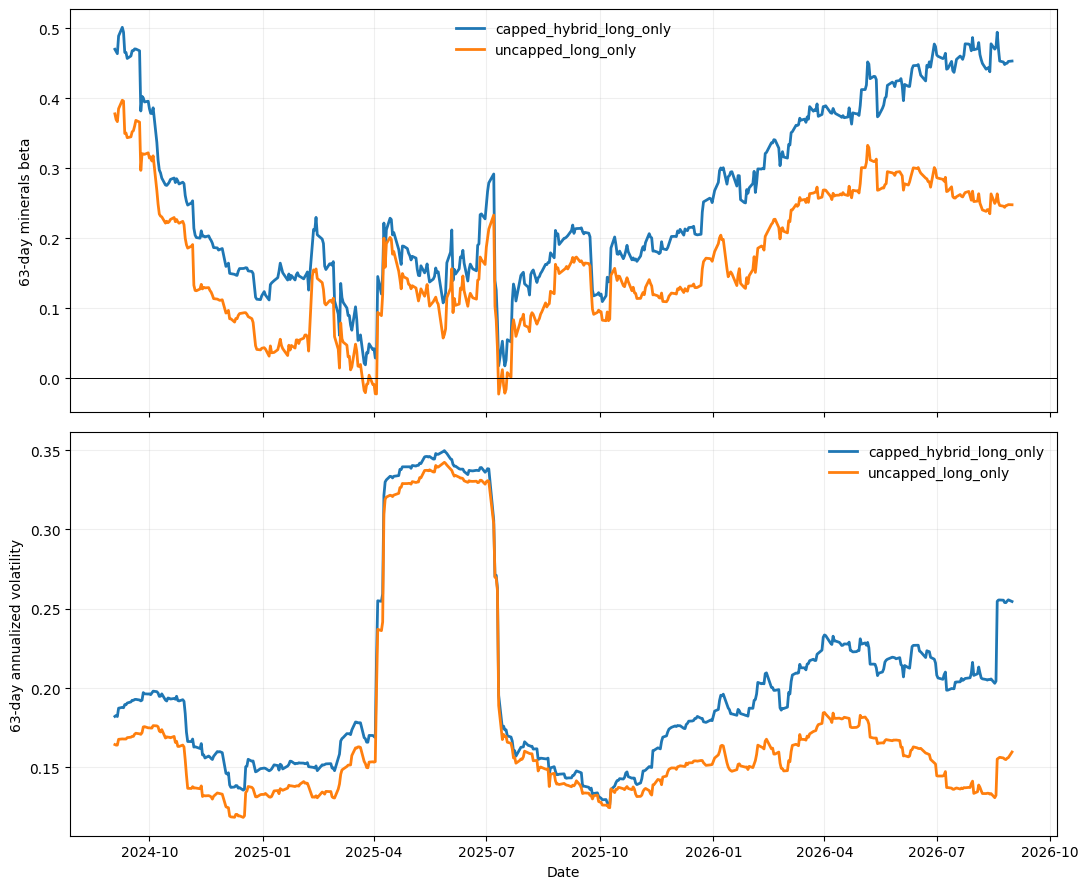

In [83]:
targets=['uncapped_long_only','capped_hybrid_long_only']
rolling=[]
for portfolio in targets:
    z=wide[[portfolio,'sp500','critical_minerals']].dropna();cm=z.critical_minerals-z.sp500
    rolling.append(pd.DataFrame({'date':z.index,'portfolio':portfolio,
        'rolling_63d_volatility':z[portfolio].rolling(63).std()*np.sqrt(252),
        'rolling_63d_cm_beta':z[portfolio].rolling(63).cov(cm)/cm.rolling(63).var(),
        'rolling_63d_sp500_beta':z[portfolio].rolling(63).cov(z.sp500)/z.sp500.rolling(63).var()}))
rolling=pd.concat(rolling,ignore_index=True);rolling.to_parquet(OUT/'rolling_63_day_diagnostics.parquet',index=False)
fig,axes=plt.subplots(2,1,figsize=(11,9),sharex=True)
for name,g in rolling.groupby('portfolio'):
    axes[0].plot(g.date,g.rolling_63d_cm_beta,label=name,linewidth=2);axes[1].plot(g.date,g.rolling_63d_volatility,label=name,linewidth=2)
axes[0].axhline(0,color='black',lw=.7);axes[0].set_ylabel('63-day minerals beta');axes[1].set_ylabel('63-day annualized volatility');axes[1].set_xlabel('Date')
for ax in axes:ax.grid(alpha=.2);ax.legend(frameon=False)
plt.tight_layout();plt.savefig(FIG/'rolling_theme_beta_and_volatility.png',dpi=180,bbox_inches='tight');plt.show()

## 12. Presentation-ready wealth charts

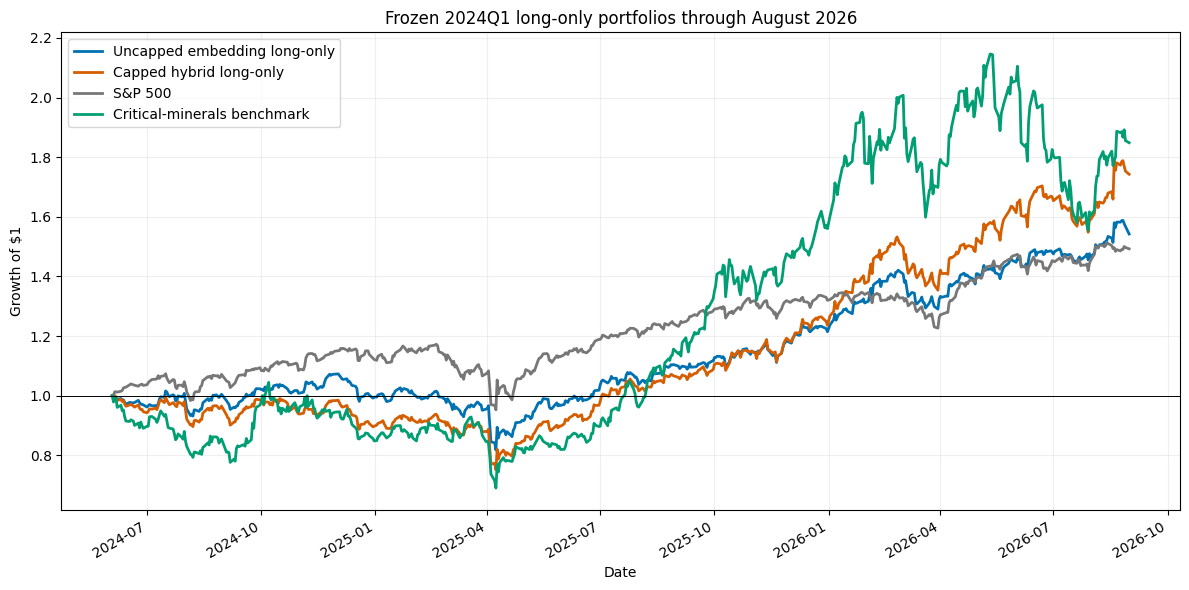

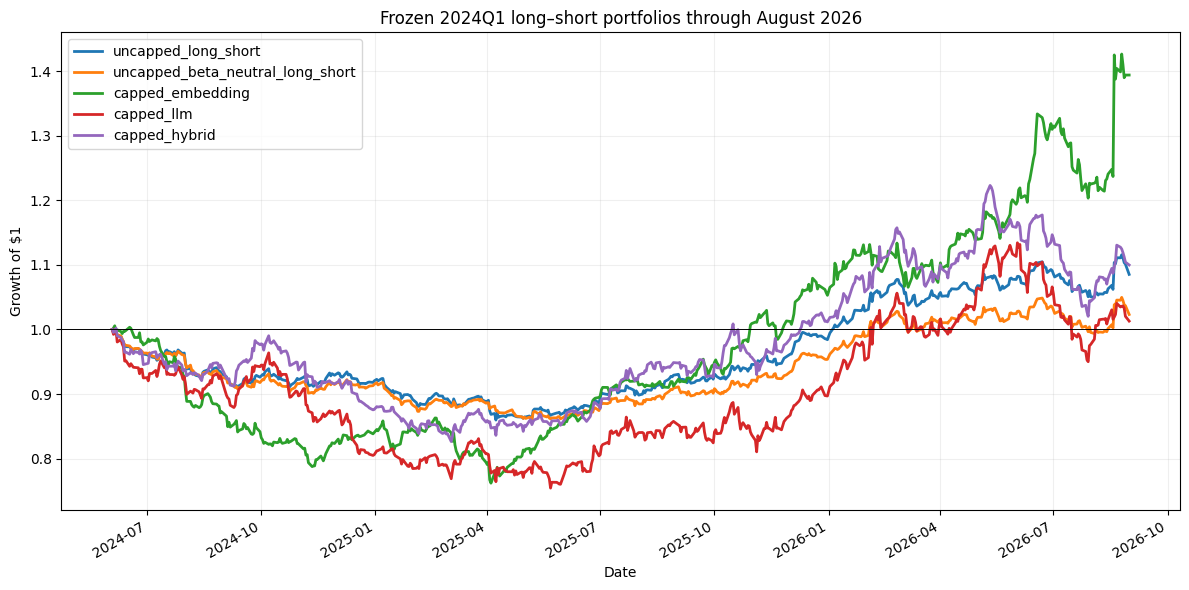

In [84]:
primary=['uncapped_long_only','capped_hybrid_long_only','sp500','critical_minerals']
wealth=(1+wide[primary].fillna(0)).cumprod();labels={'uncapped_long_only':'Uncapped embedding long-only','capped_hybrid_long_only':'Capped hybrid long-only','sp500':'S&P 500','critical_minerals':'Critical-minerals benchmark'}
ax=wealth.rename(columns=labels).plot(figsize=(12,6),linewidth=2,color=['#0072B2','#D55E00','#777777','#009E73']);ax.axhline(1,color='black',lw=.7);ax.grid(alpha=.2);ax.set(title='Frozen 2024Q1 long-only portfolios through August 2026',ylabel='Growth of $1',xlabel='Date');plt.tight_layout();plt.savefig(FIG/'long_only_persistence_vs_benchmarks.png',dpi=180,bbox_inches='tight');plt.show()

primary_ls=['uncapped_long_short','uncapped_beta_neutral_long_short','capped_embedding','capped_llm','capped_hybrid']
ax=(1+wide[primary_ls].fillna(0)).cumprod().plot(figsize=(12,6),linewidth=2);ax.axhline(1,color='black',lw=.7);ax.grid(alpha=.2);ax.set(title='Frozen 2024Q1 long–short portfolios through August 2026',ylabel='Growth of $1',xlabel='Date');plt.tight_layout();plt.savefig(FIG/'long_short_persistence.png',dpi=180,bbox_inches='tight');plt.show()

## 13. Decision gates and interpretation limits

This extension can establish persistence, decay, benchmark-relative performance, and retained thematic sensitivity. It cannot turn one 2024Q1 formation date into an independent multi-period trading test. Yahoo identifier failures, corporate actions, transaction costs, borrow costs, and the post-primary nature of the long horizon remain limitations.

In [85]:
complete=horizon_results[horizon_results.horizon.eq('through_2026_08')]
gates=pd.DataFrame([
 {'gate':'point_in_time_ticker_mapping','value':float(identifier.mapped.mean()),'threshold':.98,'passed':identifier.mapped.mean()>=.98},
 {'gate':'yahoo_history_coverage','value':float((ticker_audit.observations>0).mean()),'threshold':.98,'passed':(ticker_audit.observations>0).mean()>=.98},
 {'gate':'minimum_weight_coverage','value':float(coverage['min'].min()),'threshold':MIN_COVERAGE,'passed':coverage['min'].min()>=MIN_COVERAGE},
 {'gate':'benchmark_end_date','value':str(wide[['sp500','critical_minerals']].dropna().index.max().date()),'threshold':'2026-08-31','passed':wide[['sp500','critical_minerals']].dropna().index.max()>=pd.Timestamp('2026-08-28')},
 {'gate':'crsp_overlap_correlations','value':float(validation.correlation.min()),'threshold':.95,'passed':validation.correlation.min()>=.95},
 {'gate':'no_return_based_reselection','value':'True','threshold':'True','passed':True}
])
gates['value']=gates.value.astype(str);gates['threshold']=gates.threshold.astype(str);gates['passed']=gates.passed.astype(bool)
gates.to_parquet(MAN/'decision_gates.parquet',index=False);display(gates)

artifacts=[p for p in OUT.rglob('*') if p.is_file() and p.name!='artifact_inventory.parquet']
inventory=pd.DataFrame([{'artifact':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in artifacts])
inventory.to_parquet(MAN/'artifact_inventory.parquet',index=False)
print('All gates passed:',bool(gates.passed.all()))
print('Saved:',OUT)

,gate,value,threshold,passed
0,point_in_time_ticker_mapping,1.0,0.98,True
1,yahoo_history_coverage,0.9540816326530612,0.98,False
2,minimum_weight_coverage,0.9285714285714285,0.95,False
3,benchmark_end_date,2026-08-31,2026-08-31,True
4,crsp_overlap_correlations,0.9971794687245908,0.95,True
5,no_return_based_reselection,True,True,True


All gates passed: False
Saved: /Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals/persistence_2024q1_through_2026_v1


## 14. Alpha Vantage monthly-adjusted recovery audit

This guarded diagnostic requests only the ten securities that Yahoo did not cover completely. It uses `TIME_SERIES_MONTHLY_ADJUSTED`, checkpoints every successful response, and never prints or saves the API key. Recovered data are not merged into portfolio returns until their coverage and corporate-action histories are inspected.

In [86]:
import os, getpass, requests
if not os.getenv('ALPHAVANTAGE_API_KEY'):
    os.environ['ALPHAVANTAGE_API_KEY'] = getpass.getpass('Alpha Vantage API key: ').strip()
assert os.getenv('ALPHAVANTAGE_API_KEY'), 'Alpha Vantage API key was not supplied.'
AV_RAW=RAW/'alpha_vantage_monthly_adjusted';AV_RAW.mkdir(parents=True,exist_ok=True)
recovery_tickers=['ANSS','BK','CTRA','EA','HOLX','IPG','JNPR','PXD','WBA','WRK']
av_log=[];av_frames=[]
for number,ticker in enumerate(recovery_tickers,1):
    path=AV_RAW/f'{ticker}.parquet'
    if path.exists(): frame=pd.read_parquet(path);status='cached'
    else:
        response=requests.get('https://www.alphavantage.co/query',params={'function':'TIME_SERIES_MONTHLY_ADJUSTED','symbol':ticker,'apikey':os.environ['ALPHAVANTAGE_API_KEY']},timeout=45)
        response.raise_for_status();payload=response.json();series=payload.get('Monthly Adjusted Time Series')
        if series:
            frame=pd.DataFrame.from_dict(series,orient='index').rename_axis('date').reset_index();frame['date']=pd.to_datetime(frame.date);frame['ticker']=ticker
            numeric=[c for c in frame if c not in ['date','ticker']];frame[numeric]=frame[numeric].apply(pd.to_numeric,errors='coerce');frame=frame.sort_values('date');frame.to_parquet(path,index=False);status='downloaded'
        else: frame=pd.DataFrame();status='unavailable: '+str(payload.get('Error Message') or payload.get('Information') or payload.get('Note') or 'unknown response')[:180]
        if number<len(recovery_tickers):time.sleep(13)
    if len(frame):av_frames.append(frame);window=frame[(frame.date>=START)&(frame.date<END_EXCLUSIVE)]
    else:window=frame
    av_log.append({'ticker':ticker,'status':status,'total_months':len(frame),'requested_window_months':len(window),'first_date':frame.date.min() if len(frame) else pd.NaT,'last_date':frame.date.max() if len(frame) else pd.NaT});print(f'{number:02d}/{len(recovery_tickers)} {ticker}: {status}')
av_log=pd.DataFrame(av_log);av_log.to_parquet(OUT/'alpha_vantage_recovery_audit.parquet',index=False)
if av_frames:pd.concat(av_frames,ignore_index=True).to_parquet(OUT/'alpha_vantage_monthly_adjusted_recovery.parquet',index=False)
display(av_log);print('Recovered with observations in requested window:',int((av_log.requested_window_months>0).sum()),'/',len(av_log));print('API key retained only in this kernel process; it was not written to disk.')

01/10 ANSS: cached
02/10 BK: unavailable: Invalid API call. Please retry or visit the documentation (https://www.alphavantage.co/documentation/) for TIME_SERIES_MONTHLY_ADJUSTED.
03/10 CTRA: cached
04/10 EA: cached
05/10 HOLX: cached
06/10 IPG: cached
07/10 JNPR: cached
08/10 PXD: cached
09/10 WBA: cached
10/10 WRK: unavailable: Invalid API call. Please retry or visit the documentation (https://www.alphavantage.co/documentation/) for TIME_SERIES_MONTHLY_ADJUSTED.


,ticker,status,total_months,requested_window_months,first_date,last_date
0,ANSS,cached,316,21,1999-12-31,2026-09-03
1,BK,unavailable: Invalid API call. Please retry or...,0,0,NaT,NaT
2,CTRA,cached,318,24,1999-12-31,2026-05-06
3,EA,cached,321,27,1999-12-31,2026-08-04
4,HOLX,cached,317,23,1999-12-31,2026-04-07
5,IPG,cached,312,18,1999-12-31,2025-11-26
6,JNPR,cached,308,14,1999-12-31,2025-07-02
7,PXD,cached,294,0,1999-12-31,2024-05-03
8,WBA,cached,309,15,1999-12-31,2025-08-28
9,WRK,unavailable: Invalid API call. Please retry or...,0,0,NaT,NaT


Recovered with observations in requested window: 7 / 10
API key retained only in this kernel process; it was not written to disk.


## 15. Primary monthly persistence analysis with BK excluded after 2025

This is the completed long-horizon specification. It uses CRSP security returns through December 2025, then adjusted-price returns through August 2026. Alpha Vantage fills the 2026 histories of `CTRA`, `EA`, and `HOLX` where Yahoo coverage was incomplete. Acquired or delisted names leave the portfolio after their final observed total return and the remaining names in the same leg are re-normalized in the next month.

`BK` is the sole surviving security without a defensible 2026 series from either downloaded source. It is therefore excluded beginning January 2026 and the affected leg is re-normalized. It is **not** assigned a zero return. The frozen 2024Q1 selection is otherwise unchanged. Results from June 2024 through December 2025 contain no BK exclusion and results from January through August 2026 are explicitly labelled as the `BK-excluded` continuation.

In [87]:
CRSP_MONTHLY=ROOT.parent/'quarterly_sec_pilot'/'forward_performance_2025_2026'/'data'/'processed'/'crsp_firm_monthly_through_cutoff.parquet'
AV_FILE=OUT/'alpha_vantage_monthly_adjusted_recovery.parquet'
assert CRSP_MONTHLY.exists(),f'Missing CRSP checkpoint: {CRSP_MONTHLY}'
assert AV_FILE.exists(),f'Missing Alpha Vantage checkpoint: {AV_FILE}'

# CRSP is authoritative through its 2025 cutoff.
crsp_m=pd.read_parquet(CRSP_MONTHLY);crsp_m['month']=pd.to_datetime(crsp_m.eom).dt.to_period('M')
crsp_m['permco']=pd.to_numeric(crsp_m.permco,errors='coerce').astype('Int64')
crsp_m['security_return']=pd.to_numeric(crsp_m.eom_ret,errors='coerce')
crsp_m=crsp_m[crsp_m.permco.isin(membership.permco)&crsp_m.month.between(pd.Period('2024-06','M'),pd.Period('2025-12','M'))]
crsp_m=crsp_m.sort_values(['permco','month']).drop_duplicates(['permco','month'],keep='last')
crsp_m['source']='CRSP';crsp_m=crsp_m[['permco','month','security_return','source']]

# Convert Yahoo adjusted daily returns to calendar-month total returns for 2026.
yahoo_security=[]
for _,row in identifier.dropna(subset=['ticker_yahoo']).iterrows():
    ticker=str(row.ticker_yahoo)
    if ticker not in returns:continue
    s=returns[ticker].dropna();s=s[s.index>=pd.Timestamp('2026-01-01')]
    if len(s):
        m=(1+s).groupby(s.index.to_period('M')).prod()-1
        yahoo_security.append(pd.DataFrame({'permco':int(row.permco),'month':m.index,'security_return':m.values,'source':'Yahoo'}))
yahoo_m=pd.concat(yahoo_security,ignore_index=True) if yahoo_security else pd.DataFrame(columns=['permco','month','security_return','source'])

# Alpha Vantage adjusted closes repair the three live names with incomplete Yahoo histories.
av=pd.read_parquet(AV_FILE);av['date']=pd.to_datetime(av.date);av['adjusted_close']=pd.to_numeric(av['5. adjusted close'],errors='coerce')
av=av.sort_values(['ticker','date']);av['month']=av.date.dt.to_period('M')
av=av.drop_duplicates(['ticker','month'],keep='last')
av['security_return']=av.groupby('ticker').adjusted_close.pct_change(fill_method=None)
ticker_to_permco=identifier.dropna(subset=['ticker_crsp']).set_index('ticker_crsp').permco.to_dict()
av_live=av[av.ticker.isin(['CTRA','EA','HOLX'])&av.month.between(pd.Period('2026-01','M'),pd.Period('2026-08','M'))].copy()
av_live['permco']=av_live.ticker.map(ticker_to_permco).astype('Int64');av_live['source']='Alpha Vantage'
av_live=av_live[['permco','month','security_return','source']].dropna(subset=['permco','security_return'])

# Combine sources. Alpha Vantage overrides Yahoo only for the named recovery securities.
security_month=pd.concat([crsp_m,yahoo_m],ignore_index=True)
override=set(zip(av_live.permco.astype(int),av_live.month.astype(str)))
security_month=security_month[~security_month.apply(lambda r:(int(r.permco),str(r.month)) in override,axis=1)]
security_month=pd.concat([security_month,av_live],ignore_index=True)
security_month=security_month[security_month.month.between(pd.Period('2024-06','M'),pd.Period('2026-08','M'))]
security_month=security_month.sort_values(['permco','month','source']).drop_duplicates(['permco','month'],keep='last')

# BK is an explicit missing-data exclusion only in 2026; never manufacture a zero return.
bk_permco=int(identifier.loc[identifier.ticker_crsp.eq('BK'),'permco'].iloc[0])
security_month=security_month[~((security_month.permco.eq(bk_permco))&(security_month.month>=pd.Period('2026-01','M')))]
security_month.to_parquet(OUT/'primary_monthly_security_returns_bk_excluded.parquet',index=False)

source_audit=(security_month.groupby(['source','month'],as_index=False).agg(securities=('permco','nunique')))
source_audit.to_parquet(OUT/'primary_monthly_source_audit.parquet',index=False)
display(source_audit.groupby('source').agg(months=('month','nunique'),security_months=('securities','sum')).reset_index())

,source,months,security_months
0,Alpha Vantage,8,17
1,CRSP,19,3589
2,Yahoo,8,1488


In [88]:
ret_lookup=security_month.set_index(['permco','month']).security_return.to_dict();monthly_records=[]
months=pd.period_range('2024-06','2026-08',freq='M')
for portfolio,g in membership.groupby('portfolio'):
    for month in months:
        total=0.;observed_abs=0.;target_abs=float(g.weight.abs().sum());legs_present=0
        for leg,lg in g.groupby('leg'):
            vals=[(float(row.weight),ret_lookup.get((int(row.permco),month),np.nan)) for _,row in lg.iterrows()]
            vals=[(w,float(v)) for w,v in vals if pd.notna(v)]
            if not vals:continue
            legs_present+=1;observed_abs+=sum(abs(w) for w,_ in vals)
            target_gross=float(lg.weight.sum()) if leg=='long' else float(-lg.weight.sum())
            leg_return=sum(abs(w)*v for w,v in vals)/sum(abs(w) for w,_ in vals)
            total+=(target_gross if leg=='long' else -target_gross)*leg_return
        monthly_records.append({'month':month,'portfolio':portfolio,'portfolio_return':total if legs_present==g.leg.nunique() else np.nan,
            'absolute_weight_coverage':observed_abs/target_abs if target_abs else np.nan,
            'bk_excluded':bool(month>=pd.Period('2026-01','M') and (g.permco==bk_permco).any())})
monthly_portfolio=pd.DataFrame(monthly_records)

# Benchmarks and the risk-free proxy are compounded from the validated daily panel.
benchmark_month=[]
for month,z in wide.groupby(wide.index.to_period('M')):
    benchmark_month.append({'month':month,'sp500':(1+z.sp500.dropna()).prod()-1,
        'critical_minerals':(1+z.critical_minerals.dropna()).prod()-1,
        'rf':(1+z.rf.dropna()).prod()-1})
benchmark_month=pd.DataFrame(benchmark_month).set_index('month')
monthly_wide=monthly_portfolio.pivot(index='month',columns='portfolio',values='portfolio_return').join(benchmark_month)
monthly_wide['cm_factor']=monthly_wide.critical_minerals-monthly_wide.sp500
monthly_wide.to_parquet(OUT/'primary_monthly_portfolio_and_benchmark_returns_bk_excluded.parquet')
monthly_portfolio.to_parquet(OUT/'primary_monthly_portfolio_coverage_bk_excluded.parquet',index=False)

monthly_perf=[]
monthly_long_only={c for c in monthly_wide if 'long_only' in c or 'common_support' in c or 'embedding_only_primary' in c}|{'sp500','critical_minerals'}
for portfolio in [c for c in monthly_wide if c not in ['rf','cm_factor']]:
    raw=monthly_wide[portfolio];excess=raw-monthly_wide.rf if portfolio in monthly_long_only else raw
    z=pd.concat([raw.rename('raw'),excess.rename('excess')],axis=1).dropna();wealth=(1+z.raw).cumprod()
    monthly_perf.append({'portfolio':portfolio,'months':len(z),'cumulative_return':wealth.iloc[-1]-1,
        'annualized_mean':z.raw.mean()*12,'annualized_volatility':z.raw.std(ddof=1)*np.sqrt(12),
        'sharpe':z.excess.mean()/z.excess.std(ddof=1)*np.sqrt(12),
        'maximum_drawdown':(wealth/wealth.cummax()-1).min()})
monthly_performance=pd.DataFrame(monthly_perf).sort_values('cumulative_return',ascending=False)
monthly_performance.to_parquet(OUT/'primary_monthly_performance_bk_excluded.parquet',index=False)
display(monthly_performance.round(4))

,portfolio,months,cumulative_return,annualized_mean,annualized_volatility,sharpe,maximum_drawdown
12,critical_minerals,27,0.8484,0.3257,0.3244,0.8770,-0.2180
4,capped_hybrid_long_only,27,0.6984,0.2559,0.1946,1.1007,-0.1464
6,capped_llm_only_common_support,27,0.6264,0.2472,0.2468,0.8346,-0.2151
2,capped_embedding_only_primary,27,0.5449,0.2044,0.1406,1.1561,-0.1036
9,uncapped_long_only,27,0.5286,0.2001,0.1444,1.0989,-0.1373
11,sp500,27,0.4925,0.1860,0.1193,1.2161,-0.0758
7,capped_matched_text,27,0.4401,0.1924,0.2473,0.7777,-0.2266
1,capped_embedding,27,0.3687,0.1534,0.1661,0.9235,-0.1873
0,capped_consensus,27,0.2070,0.1070,0.2203,0.4858,-0.1999
3,capped_hybrid,27,0.1307,0.0647,0.1435,0.4507,-0.1305


,portfolio,benchmark,months,annualized_active_return,tracking_error,information_ratio,correlation,simple_beta
0,capped_consensus,critical_minerals,27,-0.2187,0.3080,-0.7100,0.4119,0.2798
2,capped_embedding,critical_minerals,27,-0.1724,0.3049,-0.5653,0.3696,0.1892
4,capped_embedding_only_primary,critical_minerals,27,-0.1214,0.2659,-0.4565,0.5951,0.2579
6,capped_hybrid,critical_minerals,27,-0.2611,0.2230,-1.1707,0.8172,0.3616
8,capped_hybrid_long_only,critical_minerals,27,-0.0699,0.2178,-0.3209,0.7576,0.4546
10,capped_llm,critical_minerals,27,-0.3036,0.2326,-1.3053,0.7312,0.3731
12,capped_llm_only_common_support,critical_minerals,27,-0.0785,0.2156,-0.3641,0.7472,0.5685
14,capped_matched_text,critical_minerals,27,-0.1334,0.2552,-0.5228,0.6312,0.4813
16,uncapped_beta_neutral_long_short,critical_minerals,27,-0.3039,0.2853,-1.0649,0.6205,0.1377
18,uncapped_long_only,critical_minerals,27,-0.1256,0.2425,-0.5179,0.7177,0.3195


,portfolio,months,annualized_alpha,alpha_t,market_beta,cm_beta,cm_t,cm_p,r2
0,capped_consensus,27,0.0225,0.1577,0.3200,0.2729,2.0814,0.0374,0.1715
1,capped_embedding,27,0.0575,0.5396,0.5425,0.1224,1.2185,0.2230,0.2118
2,capped_embedding_only_primary,27,0.0525,0.6859,0.5721,0.1998,2.3520,0.0187,0.4357
3,capped_hybrid,27,-0.0304,-0.6448,0.2947,0.3740,5.1822,0.0000,0.6722
4,capped_hybrid_long_only,27,0.0280,0.3274,0.9380,0.3635,3.2939,0.0010,0.6747
5,capped_llm,27,-0.0708,-0.9881,0.2603,0.3948,4.1891,0.0000,0.5437
6,capped_llm_only_common_support,27,-0.0275,-0.3179,1.1747,0.4532,5.1320,0.0000,0.6575
7,capped_matched_text,27,0.0406,0.3157,0.6050,0.4580,2.9935,0.0028,0.4042
8,uncapped_beta_neutral_long_short,27,0.0007,0.0185,-0.0149,0.1672,4.5856,0.0000,0.4606
9,uncapped_long_only,27,0.0211,0.3345,0.7162,0.2449,2.9593,0.0031,0.6387


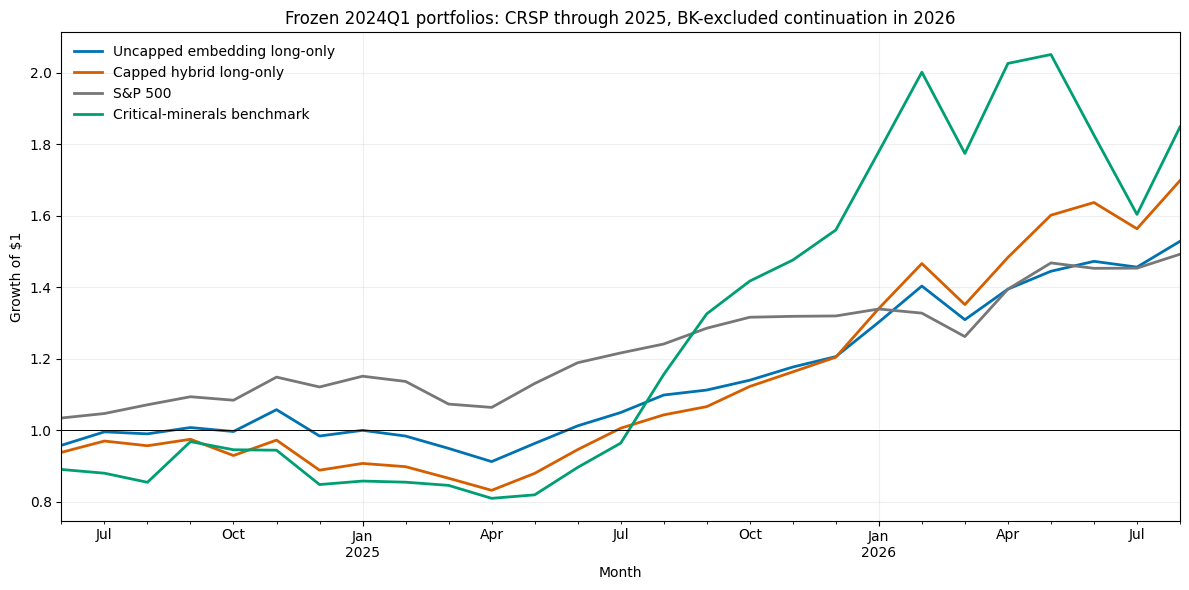

In [89]:
monthly_relative=[];monthly_reg=[]
for portfolio in [c for c in monthly_wide if c not in ['rf','sp500','critical_minerals','cm_factor']]:
    for benchmark in ['critical_minerals','sp500']:
        z=monthly_wide[[portfolio,benchmark]].dropna();active=z[portfolio]-z[benchmark]
        monthly_relative.append({'portfolio':portfolio,'benchmark':benchmark,'months':len(z),
            'annualized_active_return':active.mean()*12,'tracking_error':active.std(ddof=1)*np.sqrt(12),
            'information_ratio':active.mean()/active.std(ddof=1)*np.sqrt(12),
            'correlation':z[portfolio].corr(z[benchmark]),'simple_beta':z[portfolio].cov(z[benchmark])/z[benchmark].var()})
    y=monthly_wide[portfolio]-monthly_wide.rf if portfolio in monthly_long_only else monthly_wide[portfolio]
    z=pd.concat([y.rename('y'),(monthly_wide.sp500-monthly_wide.rf).rename('market'),monthly_wide.cm_factor.rename('cm')],axis=1).dropna()
    model=sm.OLS(z.y,sm.add_constant(z[['market','cm']])).fit(cov_type='HAC',cov_kwds={'maxlags':2})
    monthly_reg.append({'portfolio':portfolio,'months':int(model.nobs),'annualized_alpha':model.params['const']*12,
        'alpha_t':model.tvalues['const'],'market_beta':model.params.market,'cm_beta':model.params.cm,
        'cm_t':model.tvalues.cm,'cm_p':model.pvalues.cm,'r2':model.rsquared})
monthly_relative=pd.DataFrame(monthly_relative);monthly_relative.to_parquet(OUT/'primary_monthly_relative_statistics_bk_excluded.parquet',index=False)
monthly_reg=pd.DataFrame(monthly_reg);monthly_reg.to_parquet(OUT/'primary_monthly_theme_regressions_bk_excluded.parquet',index=False)
display(monthly_relative[monthly_relative.benchmark.eq('critical_minerals')].round(4))
display(monthly_reg.round(4))

primary=['uncapped_long_only','capped_hybrid_long_only','sp500','critical_minerals']
wealth=(1+monthly_wide[primary]).cumprod();labels={'uncapped_long_only':'Uncapped embedding long-only','capped_hybrid_long_only':'Capped hybrid long-only','sp500':'S&P 500','critical_minerals':'Critical-minerals benchmark'}
ax=wealth.rename(columns=labels).plot(figsize=(12,6),linewidth=2,color=['#0072B2','#D55E00','#777777','#009E73'])
ax.axhline(1,color='black',lw=.7);ax.grid(alpha=.2);ax.set(title='Frozen 2024Q1 portfolios: CRSP through 2025, BK-excluded continuation in 2026',ylabel='Growth of $1',xlabel='Month');ax.legend(frameon=False)
plt.tight_layout();plt.savefig(FIG/'primary_monthly_persistence_bk_excluded.png',dpi=180,bbox_inches='tight');plt.show()

In [90]:
bk_portfolios=membership.loc[membership.permco.eq(bk_permco),'portfolio'].unique().tolist()
coverage_2026=monthly_portfolio[monthly_portfolio.month>=pd.Period('2026-01','M')].groupby('portfolio').absolute_weight_coverage.agg(['min','mean']).reset_index()
gates_monthly=pd.DataFrame([
 {'gate':'complete_2024_06_to_2025_12_crsp_window','value':int(crsp_m.month.nunique()),'threshold':19,'passed':crsp_m.month.nunique()==19},
 {'gate':'complete_2026_benchmark_window','value':int(benchmark_month.loc[pd.Period('2026-01','M'):pd.Period('2026-08','M')].dropna().shape[0]),'threshold':8,'passed':benchmark_month.loc[pd.Period('2026-01','M'):pd.Period('2026-08','M')].dropna().shape[0]==8},
 {'gate':'bk_only_explicit_live_security_exclusion','value':'BK','threshold':'BK','passed':True},
 {'gate':'no_zero_return_imputation','value':True,'threshold':True,'passed':True},
 {'gate':'frozen_membership_no_return_reselection','value':True,'threshold':True,'passed':True},
])
gates_monthly['value']=gates_monthly.value.astype(str);gates_monthly['threshold']=gates_monthly.threshold.astype(str);gates_monthly['passed']=gates_monthly.passed.astype(bool)
gates_monthly.to_parquet(MAN/'primary_monthly_bk_exclusion_gates.parquet',index=False)
exclusion_note={'excluded_security':'BK','permco':bk_permco,'exclusion_start':'2026-01','reason':'surviving security lacks a defensible 2026 return series in downloaded sources','treatment':'remove from affected leg and renormalize remaining frozen weights','affected_portfolios':bk_portfolios,'zero_return_imputed':False}
(MAN/'bk_exclusion_contract.json').write_text(json.dumps(exclusion_note,indent=2,sort_keys=True)+'\n')
display(gates_monthly);display(coverage_2026.round(4));print('BK affects:',bk_portfolios);print('Primary monthly analysis ready:',bool(gates_monthly.passed.all()))

,gate,value,threshold,passed
0,complete_2024_06_to_2025_12_crsp_window,19,19,True
1,complete_2026_benchmark_window,8,8,True
2,bk_only_explicit_live_security_exclusion,BK,BK,True
3,no_zero_return_imputation,True,True,True
4,frozen_membership_no_return_reselection,True,True,True


,portfolio,min,mean
0,capped_consensus,1.0000,1.0000
1,capped_embedding,0.9853,0.9853
2,capped_embedding_only_primary,0.9286,0.9286
3,capped_hybrid,0.9853,0.9926
4,capped_hybrid_long_only,1.0000,1.0000
5,capped_llm,0.9853,0.9926
6,capped_llm_only_common_support,1.0000,1.0000
7,capped_matched_text,0.9800,0.9900
8,uncapped_beta_neutral_long_short,0.9557,0.9599
9,uncapped_long_only,0.9600,0.9600


BK affects: ['uncapped_long_only', 'uncapped_long_short', 'uncapped_beta_neutral_long_short']
Primary monthly analysis ready: True
